# 03 — Feature Engineering: Annual Temperature-Anomaly Forecasting

**Goal:** create a leakage-safe supervised dataset to forecast the **next year's global temperature anomaly** from information available by the current year. This is the first, interpretable forecasting target for the Climate Change Awareness Dashboard; it does not claim to produce long-range 2030/2050/2100 climate projections.

**Input:** `data/processed/climate_annual_reconstructed.csv` (the original annual climate table is used only for provenance checks). **Output:** a separate feature table under `data/processed/` and a feature audit under `reports/feature_engineering/`.

Important: reconstructed CH₄/N₂O values are estimates. Their flags are retained. They are not silently treated as observed measurements. The small annual sample means the eventual model must use chronological evaluation and simple baselines.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root whether launched from repo root or notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    candidates = [PROJECT_ROOT, *PROJECT_ROOT.parents]
    matches = [p for p in candidates if (p / "data" / "processed").exists()]
    if matches:
        PROJECT_ROOT = matches[0]

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "feature_engineering"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.exists():
    raise FileNotFoundError("Could not find data/processed. Run from the project root or notebooks/.")

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA_DIR)
print("Feature-engineering reports:", REPORT_DIR)

Project root: /Users/sarachhabra/Climate-Change-Awareness-Dashboard
Processed data: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/data/processed
Feature-engineering reports: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/reports/feature_engineering


In [2]:
annual_path = DATA_DIR / "climate_annual_reconstructed.csv"
original_path = DATA_DIR / "climate_annual.csv"
if not annual_path.exists():
    raise FileNotFoundError(f"Required input not found: {annual_path}. Run the approved preprocessing/reconstruction pipeline first.")

annual = pd.read_csv(annual_path).sort_values("year").reset_index(drop=True)
original = pd.read_csv(original_path) if original_path.exists() else None

required = {"year", "temp_anomaly", "co2", "sunspots", "nino34", "ch4", "n2o"}
missing = required - set(annual.columns)
if missing:
    raise ValueError(f"Missing required columns in reconstructed annual data: {sorted(missing)}")

annual["year"] = pd.to_numeric(annual["year"], errors="raise").astype(int)
if annual["year"].duplicated().any():
    raise ValueError("Annual data contains duplicate years.")
annual = annual.sort_values("year").reset_index(drop=True)
print("Input shape:", annual.shape)
print("Years:", annual["year"].min(), "to", annual["year"].max())
print("Columns:", annual.columns.tolist())
display(annual.head())

Input shape: (146, 22)
Years: 1880 to 2025
Columns: ['year', 'temp_anomaly', 'co2', 'co2_source', 'sunspots', 'nino34', 'ch4', 'n2o', 'ch4_observed_noaa', 'ch4_data_status', 'ch4_is_synthetic', 'ch4_method_note', 'ch4_anchor_value', 'ch4_was_filled', 'ch4_final_status', 'n2o_observed_noaa', 'n2o_data_status', 'n2o_is_synthetic', 'n2o_method_note', 'n2o_anchor_value', 'n2o_was_filled', 'n2o_final_status']


,year,temp_anomaly,co2,co2_source,sunspots,nino34,ch4,n2o,ch4_observed_noaa,ch4_data_status,...,ch4_anchor_value,ch4_was_filled,ch4_final_status,n2o_observed_noaa,n2o_data_status,n2o_is_synthetic,n2o_method_note,n2o_anchor_value,n2o_was_filled,n2o_final_status
0,1880,-0.18,289.78,ice_core,53.7,NaN,823.54,275.655172,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
1,1881,-0.09,290.01,ice_core,90.5,NaN,824.78,275.810345,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
2,1882,-0.12,290.26,ice_core,99.0,NaN,826.02,275.965517,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
3,1883,-0.18,290.51,ice_core,106.1,NaN,827.26,276.120690,NaN,synthetic_linear_interpolation,...,NaN,True,synthetic_linear_interpolation,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation
4,1884,-0.29,290.77,ice_core,105.8,NaN,828.50,276.275862,NaN,EPA_Law_Dome_historical_anchor,...,828.5,True,EPA_Law_Dome_historical_anchor,NaN,synthetic_linear_interpolation,True,historical_interpolation_from_very_sparse_EPA_...,NaN,True,synthetic_linear_interpolation


## 1. Define the prediction task

Each row represents a **forecast origin year** `t`. Features use only values from year `t` or earlier; the target is `temp_anomaly` in year `t+1`. This means the target is shifted backward one row and the final year has no target, so it is excluded.

We do not use the same-year temperature as a predictor for the same-year target. For next-year forecasting, `temp_anomaly` at year `t` is a valid lagged predictor.

In [3]:
df = annual.copy()
# Ensure the data is truly annual and sorted; avoid silently treating gaps as adjacent years.
year_diffs = df["year"].diff().dropna()
if not year_diffs.eq(1).all():
    print("WARNING: gaps exist in annual years. Lag features below mean previous available row; inspect gaps before modelling.")

# Target is next calendar year's temperature anomaly.
df["target_year"] = df["year"].shift(-1)
df["target_temp_anomaly_next_year"] = df["temp_anomaly"].shift(-1)

# Stable physical transformation: CO2 radiative forcing relative to 280 ppm.
# This is a derived proxy, not a complete climate-forcing calculation.
df["co2_forcing_w_m2"] = 5.35 * np.log(pd.to_numeric(df["co2"], errors="coerce") / 280.0)

print("Target:", "target_temp_anomaly_next_year")
print("Forecast horizon: 1 year")
print("Target missing (expected final row):", int(df["target_temp_anomaly_next_year"].isna().sum()))

Target: target_temp_anomaly_next_year
Forecast horizon: 1 year
Target missing (expected final row): 1


## 2. Create lagged and trailing-window features

- **Lags** represent historical values available at forecast time.
- **Changes** are year-over-year changes through the current year only.
- **Rolling statistics** are trailing windows ending at the current year; `center=False` prevents looking into the future.
- CH₄/N₂O synthetic flags are kept as provenance features where available. Their presence does not make estimated gas values observed data.

In [4]:
base_variables = ["temp_anomaly", "co2", "co2_forcing_w_m2", "sunspots", "nino34", "ch4", "n2o"]
for col in base_variables:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    # Lag 1 and lag 2 values. For forecast origin t, these are t-1 and t-2.
    df[f"{col}_lag1"] = df[col].shift(1)
    df[f"{col}_lag2"] = df[col].shift(2)
    # Change from the previous available year, known by the forecast origin.
    df[f"{col}_change_1y"] = df[col].diff(1)

# Trailing temperature context; current-year value and prior years only.
df["temp_anomaly_rollmean_3y"] = df["temp_anomaly"].rolling(window=3, min_periods=3, center=False).mean()
df["temp_anomaly_rollmean_5y"] = df["temp_anomaly"].rolling(window=5, min_periods=5, center=False).mean()
df["temp_anomaly_rollstd_5y"] = df["temp_anomaly"].rolling(window=5, min_periods=5, center=False).std()
df["co2_change_5y"] = df["co2"].diff(5)
df["co2_forcing_change_5y"] = df["co2_forcing_w_m2"].diff(5)

# Monotonic time index: makes the long-term trend explicit without inventing an arbitrary cycle.
df["year_index"] = df["year"] - int(df["year"].min())

# Preserve reconstruction provenance if present in the annual source.
for gas in ["ch4", "n2o"]:
    flag = f"{gas}_is_synthetic"
    if flag in df.columns:
        df[flag] = df[flag].fillna(False).astype(bool)
        df[f"{flag}_lag1"] = df[flag].shift(1).fillna(False).astype(bool)
    else:
        print(f"NOTE: {flag} is not in this input; provenance for {gas.upper()} must be obtained from the reconstruction metadata before using it in a model.")

print("Feature columns created:", len(df.columns))
display(df[["year", "target_year", "temp_anomaly", "target_temp_anomaly_next_year", "co2_forcing_w_m2", "temp_anomaly_lag1", "temp_anomaly_rollmean_5y"]].head(8))

Feature columns created: 54


/var/folders/qq/vzkmt1k13b73b46173k9_vhc0000gn/T/ipykernel_8482/1515589264.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[f"{flag}_lag1"] = df[flag].shift(1).fillna(False).astype(bool)
/var/folders/qq/vzkmt1k13b73b46173k9_vhc0000gn/T/ipykernel_8482/1515589264.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[f"{flag}_lag1"] = df[flag].shift(1).fillna(False).astype(bool)


,year,target_year,temp_anomaly,target_temp_anomaly_next_year,co2_forcing_w_m2,temp_anomaly_lag1,temp_anomaly_rollmean_5y
0,1880,1881.0,-0.18,-0.09,0.183678,NaN,NaN
1,1881,1882.0,-0.09,-0.12,0.187923,-0.18,NaN
2,1882,1883.0,-0.12,-0.18,0.192533,-0.09,NaN
3,1883,1884.0,-0.18,-0.29,0.197139,-0.12,NaN
4,1884,1885.0,-0.29,-0.34,0.201925,-0.18,-0.172
5,1885,1886.0,-0.34,-0.32,0.207074,-0.29,-0.204
6,1886,1887.0,-0.32,-0.37,0.212219,-0.34,-0.250
7,1887,1888.0,-0.37,-0.18,0.217542,-0.32,-0.300


## 3. Audit missingness and synthetic provenance

Do **not** automatically fill the remaining missing feature values with zero. Early rows are naturally missing lag/rolling features; CH₄/N₂O may also be missing where no defensible source exists. The modelling dataset below keeps rows with a known target, while feature selection and imputation are handled inside each training fold later.

In [5]:
provenance_cols = [c for c in ["ch4_is_synthetic", "n2o_is_synthetic", "ch4_is_synthetic_lag1", "n2o_is_synthetic_lag1"] if c in df.columns]
key_cols = ["year", "target_year", "target_temp_anomaly_next_year"]
feature_cols_candidate = [
    c for c in df.columns
    if c not in key_cols
    and c not in {"temp_anomaly"}  # same-year anomaly is represented by explicit lag features for the target
    and not c.endswith("_final_status")
    and not c.endswith("_source")
]

# Report feature missingness before deciding the final modelling subset.
missing_audit = pd.DataFrame({
    "column": feature_cols_candidate,
    "missing_count": [int(df[c].isna().sum()) for c in feature_cols_candidate],
    "missing_pct": [float(df[c].isna().mean() * 100) for c in feature_cols_candidate],
    "dtype": [str(df[c].dtype) for c in feature_cols_candidate],
})
missing_audit = missing_audit.sort_values(["missing_pct", "column"], ascending=[False, True])
display(missing_audit.head(20))

if provenance_cols:
    print("Provenance flag counts:")
    for c in provenance_cols:
        print(c, df[c].value_counts(dropna=False).to_dict())
else:
    print("No synthetic provenance flags found in annual input; check the reconstruction output before model training.")

,column,missing_count,missing_pct,dtype
11,n2o_observed_noaa,121,82.876712,float64
15,n2o_anchor_value,120,82.191781,float64
5,ch4_observed_noaa,104,71.232877,float64
9,ch4_anchor_value,80,54.794521,float64
31,nino34_lag2,72,49.315068,float64
32,nino34_change_1y,71,48.630137,float64
30,nino34_lag1,71,48.630137,float64
2,nino34,70,47.945205,float64
42,co2_change_5y,5,3.424658,float64
43,co2_forcing_change_5y,5,3.424658,float64


Provenance flag counts:
ch4_is_synthetic {True: 80, False: 66}
n2o_is_synthetic {True: 120, False: 26}
ch4_is_synthetic_lag1 {True: 80, False: 66}
n2o_is_synthetic_lag1 {True: 120, False: 26}


## 4. Select an initial, transparent feature set

This is a **baseline feature-engineering dataset**, not a claim that every feature should enter the final model. The target, target year, source/status text, and arbitrary cyclical year encodings are excluded. The current-year temperature anomaly is retained as `temp_anomaly_at_origin`: it is known at forecast origin year `t` and is valid for predicting year `t+1`.

In [6]:
# Explicitly name the observed temperature at forecast origin; target is the following year.
df["temp_anomaly_at_origin"] = df["temp_anomaly"]

candidate_features = [
    "temp_anomaly_at_origin", "temp_anomaly_lag1", "temp_anomaly_lag2",
    "temp_anomaly_rollmean_3y", "temp_anomaly_rollmean_5y", "temp_anomaly_rollstd_5y",
    "co2", "co2_lag1", "co2_lag2", "co2_change_1y", "co2_change_5y",
    "co2_forcing_w_m2", "co2_forcing_w_m2_lag1", "co2_forcing_w_m2_lag2", "co2_forcing_change_5y",
    "sunspots", "sunspots_lag1", "sunspots_lag2", "sunspots_change_1y",
    "nino34", "nino34_lag1", "nino34_lag2", "nino34_change_1y",
    "ch4", "ch4_lag1", "ch4_lag2", "ch4_change_1y",
    "n2o", "n2o_lag1", "n2o_lag2", "n2o_change_1y",
    "year_index",
] + provenance_cols
feature_cols = list(dict.fromkeys(c for c in candidate_features if c in df.columns))

model_table = df[["year", "target_year", "target_temp_anomaly_next_year"] + feature_cols].copy()
model_table = model_table.rename(columns={"year": "forecast_origin_year"})
# A known next-year target is required; do not drop rows based on feature missingness yet.
model_table = model_table.loc[model_table["target_temp_anomaly_next_year"].notna()].reset_index(drop=True)

assert model_table["target_year"].eq(model_table["forecast_origin_year"] + 1).all(), "Target-year alignment check failed."
assert model_table["target_temp_anomaly_next_year"].notna().all()
assert "target_temp_anomaly_next_year" not in feature_cols

print("Model table shape:", model_table.shape)
print("Forecast origins:", model_table["forecast_origin_year"].min(), "to", model_table["forecast_origin_year"].max())
print("Target years:", model_table["target_year"].min(), "to", model_table["target_year"].max())
print("Number of candidate features:", len(feature_cols))
display(model_table.head())

Model table shape: (145, 39)
Forecast origins: 1880 to 2024
Target years: 1881.0 to 2025.0
Number of candidate features: 36


,forecast_origin_year,target_year,target_temp_anomaly_next_year,temp_anomaly_at_origin,temp_anomaly_lag1,temp_anomaly_lag2,temp_anomaly_rollmean_3y,temp_anomaly_rollmean_5y,temp_anomaly_rollstd_5y,co2,...,ch4_change_1y,n2o,n2o_lag1,n2o_lag2,n2o_change_1y,year_index,ch4_is_synthetic,n2o_is_synthetic,ch4_is_synthetic_lag1,n2o_is_synthetic_lag1
0,1880,1881.0,-0.09,-0.18,NaN,NaN,NaN,NaN,NaN,289.78,...,NaN,275.655172,NaN,NaN,NaN,0,True,True,False,False
1,1881,1882.0,-0.12,-0.09,-0.18,NaN,NaN,NaN,NaN,290.01,...,1.24,275.810345,275.655172,NaN,0.155172,1,True,True,True,True
2,1882,1883.0,-0.18,-0.12,-0.09,-0.18,-0.130000,NaN,NaN,290.26,...,1.24,275.965517,275.810345,275.655172,0.155172,2,True,True,True,True
3,1883,1884.0,-0.29,-0.18,-0.12,-0.09,-0.130000,NaN,NaN,290.51,...,1.24,276.120690,275.965517,275.810345,0.155172,3,True,True,True,True
4,1884,1885.0,-0.34,-0.29,-0.18,-0.12,-0.196667,-0.172,0.076616,290.77,...,1.24,276.275862,276.120690,275.965517,0.155172,4,False,True,True,True


## 5. Visual checks

These plots check whether feature creation behaved as expected. They are not model-performance results.

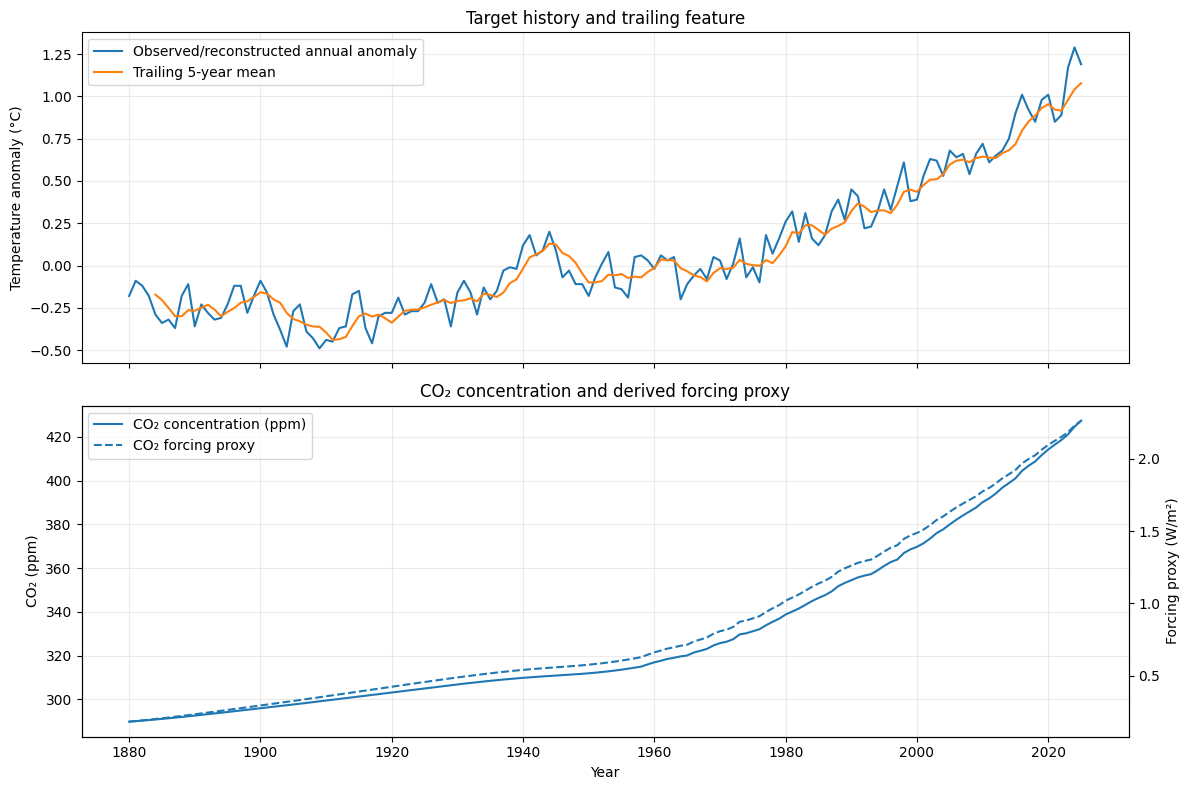

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(df["year"], df["temp_anomaly"], label="Observed/reconstructed annual anomaly")
axes[0].plot(df["year"], df["temp_anomaly_rollmean_5y"], label="Trailing 5-year mean")
axes[0].set_ylabel("Temperature anomaly (°C)")
axes[0].set_title("Target history and trailing feature")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(df["year"], df["co2"], label="CO₂ concentration (ppm)")
ax2 = axes[1].twinx()
ax2.plot(df["year"], df["co2_forcing_w_m2"], label="CO₂ forcing proxy", linestyle="--")
axes[1].set_ylabel("CO₂ (ppm)")
ax2.set_ylabel("Forcing proxy (W/m²)")
axes[1].set_xlabel("Year")
axes[1].set_title("CO₂ concentration and derived forcing proxy")
axes[1].grid(alpha=0.25)
lines = axes[1].get_lines() + ax2.get_lines()
axes[1].legend(lines, [line.get_label() for line in lines], loc="upper left")
plt.tight_layout()
plt.show()

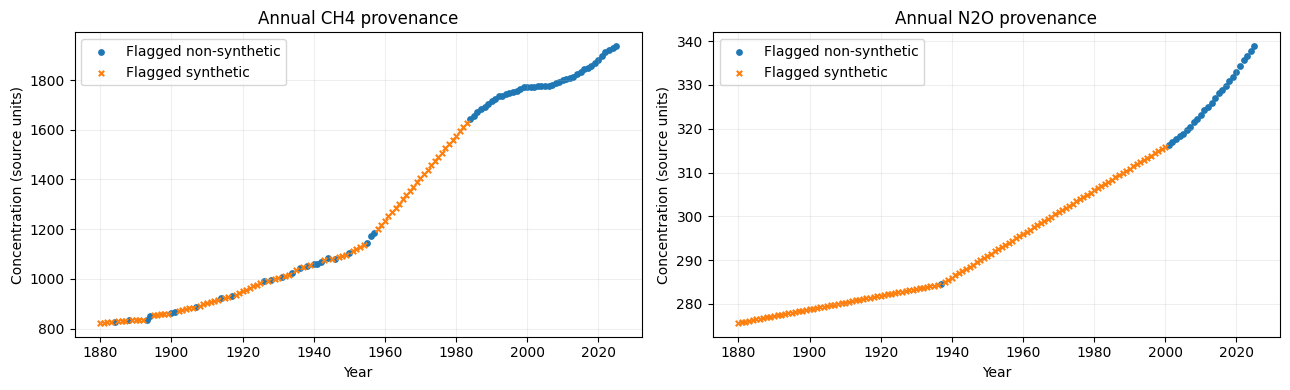

In [8]:
# Show synthetic vs non-synthetic annual gas coverage when flags exist.
flag_pairs = [("ch4", "ch4_is_synthetic"), ("n2o", "n2o_is_synthetic")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (gas, flag) in zip(axes, flag_pairs):
    if flag in df.columns:
        synthetic = df[flag].astype(bool)
        ax.scatter(df.loc[~synthetic, "year"], df.loc[~synthetic, gas], s=15, label="Flagged non-synthetic")
        ax.scatter(df.loc[synthetic, "year"], df.loc[synthetic, gas], s=15, marker="x", label="Flagged synthetic")
        ax.legend()
    else:
        ax.text(0.5, 0.5, f"{flag} unavailable", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"Annual {gas.upper()} provenance")
    ax.set_xlabel("Year")
    ax.set_ylabel("Concentration (source units)")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Save outputs without overwriting source data

The full engineered table includes rows with missing features so that the missingness is visible. The modeling table retains only rows with a known next-year target. Neither output imputes missing values. Imputation, scaling, feature selection, and any resampling must be fitted **inside the training fold only** during model training.

In [9]:
full_output = DATA_DIR / "climate_annual_features_full.csv"
model_output = DATA_DIR / "climate_annual_features_next_year.csv"
audit_output = REPORT_DIR / "feature_missingness_audit.csv"
summary_output = REPORT_DIR / "feature_engineering_summary.csv"

# Save the full feature table and supervised table separately.
df.to_csv(full_output, index=False)
model_table.to_csv(model_output, index=False)
missing_audit.to_csv(audit_output, index=False)

summary = pd.DataFrame([
    {"item": "prediction_target", "value": "next-year global temperature anomaly"},
    {"item": "forecast_horizon_years", "value": 1},
    {"item": "source_rows", "value": len(annual)},
    {"item": "supervised_rows_with_known_target", "value": len(model_table)},
    {"item": "forecast_origin_start", "value": int(model_table["forecast_origin_year"].min())},
    {"item": "forecast_origin_end", "value": int(model_table["forecast_origin_year"].max())},
    {"item": "candidate_feature_count", "value": len(feature_cols)},
    {"item": "feature_missing_values_are_imputed", "value": False},
    {"item": "synthetic_gas_flags_available", "value": bool(provenance_cols)},
])
summary.to_csv(summary_output, index=False)

display(summary)
print("Saved full feature table:", full_output)
print("Saved next-year modelling table:", model_output)
print("Saved missingness audit:", audit_output)
print("Saved summary:", summary_output)

,item,value
0,prediction_target,next-year global temperature anomaly
1,forecast_horizon_years,1
2,source_rows,146
3,supervised_rows_with_known_target,145
4,forecast_origin_start,1880
5,forecast_origin_end,2024
6,candidate_feature_count,36
7,feature_missing_values_are_imputed,False
8,synthetic_gas_flags_available,True


Saved full feature table: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/data/processed/climate_annual_features_full.csv
Saved next-year modelling table: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/data/processed/climate_annual_features_next_year.csv
Saved missingness audit: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/reports/feature_engineering/feature_missingness_audit.csv
Saved summary: /Users/sarachhabra/Climate-Change-Awareness-Dashboard/reports/feature_engineering/feature_engineering_summary.csv


## 7. Final checks and handoff

Before modelling, verify these conditions:
- The target is exactly the following calendar year's anomaly.
- No feature is calculated using values after the forecast-origin year.
- Missing values are still missing; no global imputation has been performed.
- Synthetic CH₄/N₂O flags are preserved where available.
- Evaluation must be chronological (walk-forward or expanding-window), never a random train/test split.
- Compare against at least a persistence baseline: predict next year's anomaly as the current year's anomaly.
- Annual data has only about 145 supervised examples, so keep models simple and report uncertainty. The features are candidates, not all guaranteed to improve forecasts.

**Next notebook:** model training and chronological evaluation. Before training, inspect `feature_missingness_audit.csv` and decide whether gas concentrations are included in the baseline model or evaluated in a separate sensitivity model that excludes synthetic gas estimates.